# Tweet Sentiment Classification

Classifies the overall sentiment of a tweet as positive, negative or neutral, using the SemEval 2017 Task 4 (Subtask A) corpus.

## Import necessary packages and setup functions

In [1]:
# Import necessary packages
# !pip install contractions
# !pip install emoji
# ---Standard Library---
import re
import string
import os
import copy
from collections import Counter

# ---Data Processing---
import numpy as np
import pandas as pd

# ---NLP---
import nltk
for pkg in ['stopwords', 'opinion_lexicon', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, opinion_lexicon
from nltk.stem import WordNetLemmatizer
import contractions
import emoji

# ---Feature Engineering---
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from scipy.sparse import csr_matrix, hstack

# ---Visualisation---
import matplotlib.pyplot as plt
import seaborn as sns

# ---Eval---
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, confusion_matrix
)

# ---Model Selection---
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# ---Traditional Models---
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# ---Deep Learning---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

In [2]:
lemmatizer = WordNetLemmatizer()

# Build stop words list but keep negation words
stop_words = set(stopwords.words('english'))
stop_words.difference_update({'no', 'not', 'nor'})

positive_words = set(opinion_lexicon.positive())
negative_words = set(opinion_lexicon.negative())

def clean_text(text):
    try:
        # Convert text to lowercase
        text = text.lower()
        
        # Expand contractions (e.g., "can't" -> "cannot")
        text = contractions.fix(text)
        
        # Remove URLs
        text = re.sub(r'http\S+', '', text)

        # Remove mentions (e.g., @username)
        text = re.sub(r'@\w+', '', text)
        
        # Remove the hashtag symbol but keep the word (or you could choose to keep it)
        text = re.sub(r'#', '', text)
        
        # Convert emojis to descriptive text (e.g., "😊" -> ":smiling_face_with_smiling_eyes:")
        text = emoji.demojize(text)
        
        # Remove punctuation
        text = text.translate(str.maketrans('', '', string.punctuation))
        
        # Normalize elongated words (e.g., "soooo" -> "soo")
        text = re.sub(r'(.)\1{2,}', r'\1', text)
        
        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text).strip()

        # Tokenize the text into words
        tokens = text.split()
        
        # Remove stop words (keeping negation words since they're removed from stop_words above)
        tokens = [word for word in tokens if word not in stop_words]
        
        # Lemmatize or stem tokens
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

        # print("Re-joining")
        # Re-join tokens into a cleaned string
        cleaned_text = " ".join(tokens)

        return cleaned_text

    except:
        print(text)
        return text

def pos_counts(text):
    """
    Tokenizes the cleaned tweet text (assuming words are separated by whitespace)
    and returns a list of counts for adjectives, nouns, verbs, and adverbs.
    """
    tokens = text.split()  # simple tokenization based on whitespace
    tags = nltk.pos_tag(tokens)
    adjectives = sum(1 for word, tag in tags if tag.startswith('JJ'))
    nouns      = sum(1 for word, tag in tags if tag.startswith('NN'))
    verbs      = sum(1 for word, tag in tags if tag.startswith('VB'))
    adverbs    = sum(1 for word, tag in tags if tag.startswith('RB'))
    return [adjectives, nouns, verbs, adverbs]

def lexicon_features(text):
    tokens = text.split()
    pos_count = sum(1 for token in tokens if token in positive_words)
    neg_count = sum(1 for token in tokens if token in negative_words)
    return [pos_count, neg_count]

# Skeleton: Evaluation code for the test sets
def read_test(testset):
    '''
    readin the testset and return a dictionary
    :param testset: str, the file name of the testset to compare
    '''
    id_gts = {}
    with open(testset, 'r', encoding='utf8') as fh:
        for line in fh:
            fields = line.split('\t')
            tweetid = fields[0]
            gt = fields[1]

            id_gts[tweetid] = gt

    return id_gts


def confusion(id_preds, testset, classifier):
    '''
    print the confusion matrix of {'positive', 'netative'} between preds and testset
    :param id_preds: a dictionary of predictions formated as {<tweetid>:<sentiment>, ... }
    :param testset: str, the file name of the testset to compare
    :classifier: str, the name of the classifier
    '''
    id_gts = read_test(testset)

    gts = []
    for m, c1 in id_gts.items():
        if c1 not in gts:
            gts.append(c1)

    gts = ['positive', 'negative', 'neutral']

    conf = {}
    for c1 in gts:
        conf[c1] = {}
        for c2 in gts:
            conf[c1][c2] = 0

    for tweetid, gt in id_gts.items():
        if tweetid in id_preds:
            pred = id_preds[tweetid]
        else:
            pred = 'neutral'
        conf[pred][gt] += 1

    print(''.ljust(12) + '  '.join(gts))

    for c1 in gts:
        print(c1.ljust(12), end='')
        for c2 in gts:
            if sum(conf[c1].values()) > 0:
                print('%.3f     ' % (conf[c1][c2] / float(sum(conf[c1].values()))), end='')
            else:
                print('0.000     ', end='')
        print('')

    print('')


def evaluate(id_preds, testset, classifier):
    '''
    print the macro-F1 score of {'positive', 'netative'} between preds and testset
    :param id_preds: a dictionary of predictions formated as {<tweetid>:<sentiment>, ... }
    :param testset: str, the file name of the testset to compare
    :classifier: str, the name of the classifier
    '''
    id_gts = read_test(testset)

    acc_by_class = {}
    for gt in ['positive', 'negative', 'neutral']:
        acc_by_class[gt] = {'tp': 0, 'fp': 0, 'tn': 0, 'fn': 0}

    catf1s = {}

    ok = 0
    for tweetid, gt in id_gts.items():
        if tweetid in id_preds:
            pred = id_preds[tweetid]
        else:
            pred = 'neutral'

        if gt == pred:
            ok += 1
            acc_by_class[gt]['tp'] += 1
        else:
            acc_by_class[gt]['fn'] += 1
            acc_by_class[pred]['fp'] += 1

    catcount = 0
    itemcount = 0
    macro = {'p': 0, 'r': 0, 'f1': 0}
    micro = {'p': 0, 'r': 0, 'f1': 0}
    semevalmacro = {'p': 0, 'r': 0, 'f1': 0}

    microtp = 0
    microfp = 0
    microtn = 0
    microfn = 0
    for cat, acc in acc_by_class.items():
        catcount += 1

        microtp += acc['tp']
        microfp += acc['fp']
        microtn += acc['tn']
        microfn += acc['fn']

        p = 0
        if (acc['tp'] + acc['fp']) > 0:
            p = float(acc['tp']) / (acc['tp'] + acc['fp'])

        r = 0
        if (acc['tp'] + acc['fn']) > 0:
            r = float(acc['tp']) / (acc['tp'] + acc['fn'])

        f1 = 0
        if (p + r) > 0:
            f1 = 2 * p * r / (p + r)

        catf1s[cat] = f1

        n = acc['tp'] + acc['fn']

        macro['p'] += p
        macro['r'] += r
        macro['f1'] += f1

        if cat in ['positive', 'negative']:
            semevalmacro['p'] += p
            semevalmacro['r'] += r
            semevalmacro['f1'] += f1

        itemcount += n

    micro['p'] = float(microtp) / float(microtp + microfp)
    micro['r'] = float(microtp) / float(microtp + microfn)
    micro['f1'] = 2 * float(micro['p']) * micro['r'] / float(micro['p'] + micro['r'])

    semevalmacrof1 = semevalmacro['f1'] / 2

    print(testset + ' (' + classifier + '): %.3f' % semevalmacrof1)

# --------Prediction Functions--------

def get_eval(features, df, model):
    """
    Predict sentiments from sparse features and return a dictionary
    
    Args:
        features (csr_matrix): Sparse matrix of features
        df (DataFrame): test_dfs
        model: Trained sklearn model
    """
    preds_dict = {}
    preds = model.predict(features)  # Vectorised prediction
    tweet_ids = df["tweet_id"].astype(str).values

    for tweet_id, pred in zip(tweet_ids, preds):
        preds_dict[tweet_id] = pred

    return preds_dict

def get_eval_lstm(X_tensor, df, model, device='cpu', batch_size=64):
    """
    Predict sentiment using a PyTorch LSTM model and return dictionary with string labels.
    
    Args:
        X_tensor (torch.Tensor): Token index tensor of shape [n_samples, seq_len].
        df (pd.DataFrame): Must include 'tweet_id' aligned row-by-row with X_tensor.
        model (nn.Module): A trained LSTM-based model (in eval mode) outputting [batch_size, num_classes].
        device (str): 'cpu' or 'cuda'.
        batch_size (int): Batch size for inference.
    
    Returns:
        dict: {tweet_id (str): predicted_label (str)}, e.g. { '12345': 'positive', ... }
    """
    label_map = {
        0: 'positive',
        1: 'negative',
        2: 'neutral'
    }

    preds_dict = {}
    tweet_ids = df["tweet_id"].astype(str).values

    model.eval()
    model.to(device)

    all_preds = []
    with torch.no_grad():
        for start_idx in range(0, len(X_tensor), batch_size):
            end_idx = start_idx + batch_size
            x_batch = X_tensor[start_idx:end_idx].to(device)

            logits = model(x_batch)
            batch_preds = logits.argmax(dim=1).cpu().numpy()  # numeric classes
            all_preds.extend(batch_preds)

    for tweet_id, numeric_label in zip(tweet_ids, all_preds):
        preds_dict[tweet_id] = label_map[numeric_label]

    return preds_dict

def var1_format(file_path):
	df = pd.read_csv(file_path, names=["tweet_id", "sentiment", "text"],delimiter="\t")
	df["text"] = df["text"].apply(lambda x: clean_text(x))
		
	var1_lex = csr_matrix(np.array([lexicon_features(t) for t in df["text"]]))
	var1_counts = count_vect.transform(df["text"])
	X_var1 = hstack([var1_counts, var1_lex])
	return X_var1
	
def var2_format(file_path):
	df = pd.read_csv(file_path, names=["tweet_id", "sentiment", "text"],delimiter="\t")
	df["text"] = df["text"].apply(lambda x: clean_text(x))

	var2_lex_features = [lexicon_features(text) for text in df["text"]]
	var2_lex_sparse = csr_matrix(np.array(var2_lex_features))
	var2_tfidf = tfidf.transform(df["text"])
	X_var2 = hstack([var2_tfidf, var2_lex_sparse])
	return X_var2

def LSTM_format(file_path):
	df = pd.read_csv(file_path, names=["tweet_id", "sentiment", "text"],delimiter="\t")
	df["text"] = df["text"].apply(lambda x: clean_text(x))
	
	lstm_seq = [text_to_sequence(text, vocab, max_length) for text in df["text"]]
	lstm_tensor = torch.LongTensor(lstm_seq).to(device)
	return lstm_tensor

def get_df(file_path):
	df = pd.read_csv(file_path, names=["tweet_id", "sentiment", "text"],delimiter="\t")
	# df["text"] = df["text"].apply(lambda x: clean_text(x))
	return df

# Evaluate model on a file
def eval_on_file(new_test_path, select_model="MaxEnt"):
    extra_test_path = os.path.join(data_path, new_test_path)
    extra_test_df = get_df(extra_test_path)

    if select_model == "MaxEnt":
        MaxEnt_extra_test = var1_format(extra_test_path)
        MaxEnt_preds = get_eval(MaxEnt_extra_test, extra_test_df, model=best_lr)
        score = evaluate(MaxEnt_preds, extra_test_path, "MaxEnt")
        return score

    elif select_model == "LSVC":
        LSVC_extra_test = var1_format(extra_test_path)
        LSVC_preds = get_eval(LSVC_extra_test, extra_test_df, model=best_linear_svc)
        score = evaluate(LSVC_preds, extra_test_path, "LSVC")
        return score

    elif select_model == "LSTM":
        LSTM_extra_test = LSTM_format(extra_test_path)
        LSTM_preds = get_eval_lstm(LSTM_extra_test, extra_test_df, model=model, device=device, batch_size=64)
        score = evaluate(LSTM_preds, extra_test_path, "LSTM")
        return score

    else:
        raise ValueError("Invalid model name. Choose from 'MaxEnt', 'LSVC', 'LSTM'.")

def plot_confusion_matrix(y_true, y_pred, classes=['positive','negative','neutral'], title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

In [3]:
# Set to True to re-run the full grid search over every model and feature set (slow).
# Results from the last full run are in Model Stats.csv.
full_model_search = False

## Reading in Data

In [4]:
# Define data_path to the folder where all the .txts for tweet data is. By default this is in my "semeval-tweets" folder. 
data_path = "semeval-tweets"
# testsets = ['twitter-test1.txt', 'twitter-test2.txt', 'twitter-test3.txt']

In [5]:
train = pd.read_csv(os.path.join(data_path, "twitter-training-data.txt"), names=["tweet_id", "sentiment", "text"],delimiter="\t")
val = pd.read_csv(os.path.join(data_path, "twitter-dev-data.txt"), names=["tweet_id", "sentiment", "text"],delimiter="\t")

test_1 = pd.read_csv(os.path.join(data_path, "twitter-test1.txt"), names=["tweet_id", "sentiment", "text"],delimiter="\t")
test_2 = pd.read_csv(os.path.join(data_path, "twitter-test2.txt"), names=["tweet_id", "sentiment", "text"],delimiter="\t")
test_3 = pd.read_csv(os.path.join(data_path, "twitter-test3.txt"), names=["tweet_id", "sentiment", "text"],delimiter="\t")

df_objects = [train, val, test_1, test_2, test_3]

## Preprocessing

In [6]:
for df in df_objects:
    df["text"] = df["text"].apply(lambda x: clean_text(x))

val.sample(frac=1.0).head()

,tweet_id,sentiment,text
1796,414883126180539322,negative,heart boko haram huge issue poverty people no ...
59,888583634771483094,positive,magic mike xxlwel boyit way better 1st
1956,72405796124512623,neutral,today bet came feeling confident tomorrow bet ...
724,367522824923984426,neutral,somalia arrive uganda 8 november give team tim...
145,5469868534434730,neutral,halo counter lineup hit 252 103 career ab v bl...


### CountVectorizer (Raw Counts) + Sentiment Lexicon Features

In [7]:
# Compute lexicon features
train_lex_features = [lexicon_features(text) for text in train["text"]]
val_lex_features   = [lexicon_features(text) for text in val["text"]]

# Convert to sparse matrices
train_lex_sparse = csr_matrix(np.array(train_lex_features))
val_lex_sparse   = csr_matrix(np.array(val_lex_features))

# CountVectorizer on unigrams and bigrams
count_vect = CountVectorizer(ngram_range=(1, 2))
X_train_counts = count_vect.fit_transform(train["text"])
X_val_counts   = count_vect.transform(val["text"])

# Combine count and lexicon features
X_train_V1 = hstack([X_train_counts, train_lex_sparse])
X_val_V1   = hstack([X_val_counts, val_lex_sparse])

y_train = train["sentiment"]
y_val   = val["sentiment"]

print("V1: CountVectorizer + Sentiment Lexicon Features")
print("Combined feature matrix shape (train):", X_train_V1.shape)
print("Training class distribution:", Counter(y_train))

V1: CountVectorizer + Sentiment Lexicon Features
Combined feature matrix shape (train): (45026, 352835)
Training class distribution: Counter({'neutral': 20749, 'positive': 15960, 'negative': 8317})


### TF-IDF + Sentiment Lexicon Features

In [8]:
# # Compute lexicon features for train and validation texts
train_lex_features = [lexicon_features(text) for text in train["text"]]
val_lex_features   = [lexicon_features(text) for text in val["text"]]

# Convert lexicon feature lists to sparse matrices
train_lex_sparse = csr_matrix(np.array(train_lex_features))
val_lex_sparse   = csr_matrix(np.array(val_lex_features))

# Create TF-IDF features on cleaned text
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(train["text"])
X_val_tfidf   = tfidf.transform(val["text"])

# Combine TF-IDF features with lexicon features
X_train_V2 = hstack([X_train_tfidf, train_lex_sparse])
X_val_V2   = hstack([X_val_tfidf, val_lex_sparse])

y_train = train["sentiment"]
y_val   = val["sentiment"]

print("V2: TF-IDF + Sentiment Lexicon Features")
print("Combined feature matrix shape (train):", X_train_V2.shape)
print("Training class distribution:", Counter(y_train))

V2: TF-IDF + Sentiment Lexicon Features
Combined feature matrix shape (train): (45026, 45390)
Training class distribution: Counter({'neutral': 20749, 'positive': 15960, 'negative': 8317})


## Trad Model Building

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

val_path = os.path.join(data_path, "twitter-dev-data.txt")

val_1 = var1_format(val_path)
val_2 = var2_format(val_path)

### MaxEnt (LogReg)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


C:\Users\Dhyey\anaconda3\envs\nlp-sentiment-analysis\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Best Logistic Regression C: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best cross-val F1 (macro): 0.6420744386239213
semeval-tweets\twitter-dev-data.txt (MaxEntV1): 0.631


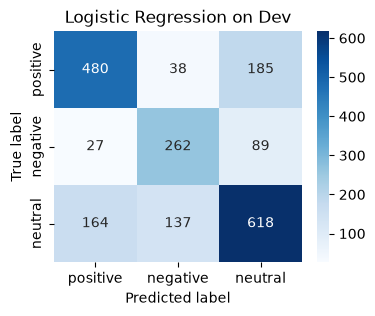

In [10]:
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')

param_grid_lr = [
    {
        'penalty': ['l2'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'solver': ['lbfgs', 'liblinear'],
    },
    {
        'penalty': ['l1'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'solver': ['liblinear'],
    }
]

grid_lr = GridSearchCV(log_reg, param_grid_lr, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
grid_lr.fit(X_train_V1, y_train)

print("Best Logistic Regression C:", grid_lr.best_params_)
print("Best cross-val F1 (macro):", grid_lr.best_score_)

best_lr = grid_lr.best_estimator_
y_dev_pred_lr = best_lr.predict(X_val_V1)

preds_dict = get_eval(val_1, val, model=best_lr)

evaluate(preds_dict, val_path, "MaxEntV1")

plot_confusion_matrix(y_val, y_dev_pred_lr, title="Logistic Regression on Dev")

### LinearSVC

Fitting 3 folds for each of 32 candidates, totalling 96 fits


Best LinearSVC parameters: {'C': 0.1, 'dual': False, 'loss': 'squared_hinge', 'penalty': 'l1'}
Best cross-val F1 (macro): 0.6437304806591657
semeval-tweets\twitter-dev-data.txt (LSVC1): 0.623


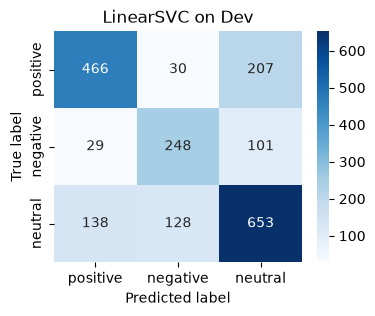

In [11]:
lin_svc = LinearSVC(class_weight='balanced', max_iter=500)

param_grid_linear = [
    {
        'penalty': ['l2'],
        'loss': ['hinge'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [True]  # only valid option for hinge with l2
    },
    {
        'penalty': ['l2'],
        'loss': ['squared_hinge'],
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [True, False]  # both are valid for squared_hinge
    },
    {
        'penalty': ['l1'],
        'loss': ['squared_hinge'],  # only option for l1
        'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
        'dual': [False]  # dual must be False for l1 penalty
    }
]

grid_linear = GridSearchCV(lin_svc, param_grid_linear, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
grid_linear.fit(X_train_V1, y_train)

print("Best LinearSVC parameters:", grid_linear.best_params_)
print("Best cross-val F1 (macro):", grid_linear.best_score_)

best_linear_svc = grid_linear.best_estimator_
y_dev_pred_linear = best_linear_svc.predict(X_val_V1)

preds_dict = get_eval(val_1, val, model=best_linear_svc)

evaluate(preds_dict, val_path, "LSVC1")

plot_confusion_matrix(y_val, y_dev_pred_linear, title="LinearSVC on Dev")

## Full model search with all tested models and feature embedding variations (optional | only enable if wanting to see full model comparison)

#### MaxEnt

In [12]:
if full_model_search:
    log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')

    param_grid_lr = [
        {
            'penalty': ['l2'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'solver': ['lbfgs', 'liblinear'],
        },
        {
            'penalty': ['l1'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'solver': ['liblinear'],
        }
    ]

    grid_lr = GridSearchCV(log_reg, param_grid_lr, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
    grid_lr.fit(X_train_V1, y_train)

    print("Best Logistic Regression C:", grid_lr.best_params_)

    best_lr = grid_lr.best_estimator_

    preds_dict = get_eval(val_1, val, model=best_lr)

    evaluate(preds_dict, val_path, "MaxEntV1")

In [13]:
if full_model_search:

    log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')

    param_grid_lr = [
        {
            'penalty': ['l2'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'solver': ['lbfgs', 'liblinear'],
        },
        {
            'penalty': ['l1'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'solver': ['liblinear'],
        }
    ]

    grid_lr = GridSearchCV(log_reg, param_grid_lr, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
    grid_lr.fit(X_train_V2, y_train)

    print("Best Logistic Regression C:", grid_lr.best_params_)

    best_lr = grid_lr.best_estimator_

    preds_dict = get_eval(val_2, val, model=best_lr)

    evaluate(preds_dict, val_path, "MaxEntV2")

#### Multinomial Naive Bayes

In [14]:
if full_model_search:

    from sklearn.naive_bayes import MultinomialNB
    nb = MultinomialNB()

    param_grid_nb = {
        'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
        'fit_prior': [True, False]
    }

    # Use StratifiedKFold for cross-validation to preserve class distributions.
    grid_nb = GridSearchCV(nb, param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
    grid_nb.fit(X_train_V1, y_train)

    print("Best NB parameters:", grid_nb.best_params_)

    # --- Step 6: Evaluate on Validation Set ---
    best_nb = grid_nb.best_estimator_

    preds_dict = get_eval(val_1, val, model=best_nb)

    evaluate(preds_dict, val_path, "MNB1")

In [15]:
if full_model_search:

    from sklearn.naive_bayes import MultinomialNB
    nb = MultinomialNB()

    param_grid_nb = {
        'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
        'fit_prior': [True, False]
    }

    # Use StratifiedKFold for cross-validation to preserve class distributions.
    grid_nb = GridSearchCV(nb, param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
    grid_nb.fit(X_train_V2, y_train)

    print("Best NB parameters:", grid_nb.best_params_)

    # --- Step 6: Evaluate on Validation Set ---
    best_nb = grid_nb.best_estimator_

    preds_dict = get_eval(val_2, val, model=best_nb)

    evaluate(preds_dict, val_path, "MNB2")

#### SGDClassifier

In [16]:
if full_model_search:

    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import GridSearchCV, StratifiedKFold

    # Instantiate the SGDClassifier with basic settings.
    sgd = SGDClassifier(random_state=42, class_weight='balanced', max_iter=1000, tol=1e-3)

    # Expanded parameter grid including eta0.
    param_grid_sgd = {
        'loss': ['hinge', 'log_loss'],                   # 'hinge' for SVM-like, 'log_loss' for logistic regression
        'penalty': ['l2', 'l1', 'elasticnet'],            # Regularization types
        'alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10],         # Regularization strength
        'learning_rate': ['optimal', 'constant', 'invscaling'],  # Different learning rate strategies
        'eta0': [0.01, 0.1, 1.0]                          # Initial learning rate (must be > 0)
    }


    # Set up grid search with macro F1 as the scoring metric.
    grid_sgd = GridSearchCV(sgd, param_grid_sgd, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
    grid_sgd.fit(X_train_V1, y_train)

    print("Best SGD parameters:", grid_sgd.best_params_)

    # Evaluate the best estimator on the validation set.
    best_sgd = grid_sgd.best_estimator_

    preds_dict = get_eval(val_1, val, model=best_sgd)

    evaluate(preds_dict, val_path, "SGD1")

In [17]:
if full_model_search:

    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import GridSearchCV, StratifiedKFold

    # Instantiate the SGDClassifier with basic settings.
    sgd = SGDClassifier(random_state=42, class_weight='balanced', max_iter=1000, tol=1e-3)

    # Expanded parameter grid including eta0.
    param_grid_sgd = {
        'loss': ['hinge', 'log_loss'],                   # 'hinge' for SVM-like, 'log_loss' for logistic regression
        'penalty': ['l2', 'l1', 'elasticnet'],            # Regularization types
        'alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10],         # Regularization strength
        'learning_rate': ['optimal', 'constant', 'invscaling'],  # Different learning rate strategies
        'eta0': [0.01, 0.1, 1.0]                          # Initial learning rate (must be > 0)
    }


    # Set up grid search with macro F1 as the scoring metric.
    grid_sgd = GridSearchCV(sgd, param_grid_sgd, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=1)
    grid_sgd.fit(X_train_V2, y_train)

    print("Best SGD parameters:", grid_sgd.best_params_)

    # Evaluate the best estimator on the validation set.
    best_sgd = grid_sgd.best_estimator_

    preds_dict = get_eval(val_2, val, model=best_sgd)

    evaluate(preds_dict, val_path, "SGD2")

#### LinearSVC

In [18]:
if full_model_search:

    lin_svc = LinearSVC(class_weight='balanced', max_iter=500)  # allow more iterations for convergence

    param_grid_linear = [
        {
            'penalty': ['l2'],
            'loss': ['hinge'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [True]  # only valid option for hinge with l2
        },
        {
            'penalty': ['l2'],
            'loss': ['squared_hinge'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [True, False]  # both are valid for squared_hinge
        },
        {
            'penalty': ['l1'],
            'loss': ['squared_hinge'],  # only option for l1
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [False]  # dual must be False for l1 penalty
        }
    ]

    grid_linear = GridSearchCV(lin_svc, param_grid_linear, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
    grid_linear.fit(X_train_V1, y_train)

    print("Best LinearSVC parameters:", grid_linear.best_params_)

    best_linear_svc = grid_linear.best_estimator_

    preds_dict = get_eval(val_1, val, model=best_linear_svc)

    evaluate(preds_dict, val_path, "LSVC1")

In [19]:
if full_model_search:

    lin_svc = LinearSVC(class_weight='balanced', max_iter=500)  # allow more iterations for convergence

    param_grid_linear = [
        {
            'penalty': ['l2'],
            'loss': ['hinge'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [True]  # only valid option for hinge with l2
        },
        {
            'penalty': ['l2'],
            'loss': ['squared_hinge'],
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [True, False]  # both are valid for squared_hinge
        },
        {
            'penalty': ['l1'],
            'loss': ['squared_hinge'],  # only option for l1
            'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
            'dual': [False]  # dual must be False for l1 penalty
        }
    ]

    grid_linear = GridSearchCV(lin_svc, param_grid_linear, scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
    grid_linear.fit(X_train_V2, y_train)

    print("Best LinearSVC parameters:", grid_linear.best_params_)

    best_linear_svc = grid_linear.best_estimator_

    preds_dict = get_eval(val_2, val, model=best_linear_svc)

    evaluate(preds_dict, val_path, "LSVC2")

## LSTM

### Define Functions

In [20]:
def build_vocab(texts, max_vocab_size=5000):
    """
    Build a vocabulary dictionary from a list of cleaned text strings.
    Reserve index 0 for <PAD> and index 1 for <UNK>.
    """
    counter = Counter()
    for text in texts:
        tokens = text.split()  # assuming text is already cleaned
        counter.update(tokens)
    most_common = counter.most_common(max_vocab_size - 2)
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for idx, (word, freq) in enumerate(most_common, start=2):
        vocab[word] = idx
    return vocab

def load_glove_embeddings(glove_file_path, vocab, embedding_dim=100):
    """
    Load pre-trained GloVe embeddings from a file.
    Returns an embedding matrix of shape (vocab_size, embedding_dim) as a torch.FloatTensor.
    """
    # Initialize embedding matrix with random values.
    embeddings = np.random.uniform(-0.25, 0.25, (len(vocab), embedding_dim))
    # Set the embedding for <PAD> (index 0) to zeros.
    embeddings[0] = np.zeros(embedding_dim)
    
    with open(glove_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.strip().split()
            word = values[0]
            if word in vocab:
                vector = np.asarray(values[1:], dtype='float32')
                embeddings[vocab[word]] = vector
    return torch.FloatTensor(embeddings)

def text_to_sequence(text, vocab, max_length):
    """
    Convert cleaned text into a sequence of token indices.
    Pads or truncates to max_length.
    """
    tokens = text.split()  # assume text is already cleaned
    seq = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    if len(seq) < max_length:
        seq = seq + [vocab["<PAD>"]] * (max_length - len(seq))
    else:
        seq = seq[:max_length]
    return seq

### Vocab and Embeddings

In [21]:
embed_path = os.path.join(data_path, "embeddings")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build vocabulary from the training text.
vocab = build_vocab(train["text"].tolist(), max_vocab_size=5000)
vocab_size = len(vocab)
print("Vocabulary size:", vocab_size)

# Path to the GloVe file in the "embeddings" folder.
glove_file = os.path.join(embed_path, "glove.6B.100d.txt")
embedding_dim = 100
embedding_matrix = load_glove_embeddings(glove_file, vocab, embedding_dim=embedding_dim)
print("Embedding matrix shape:", embedding_matrix.shape)

# Calculate and set max_length according to 95th percentile of training set
token_lengths = train["text"].apply(lambda x: len(x.split()))
max_length = int(np.percentile(token_lengths, 95))

# Convert training and validation texts to sequences.
train_sequences = [text_to_sequence(text, vocab, max_length) for text in train["text"]]
val_sequences   = [text_to_sequence(text, vocab, max_length) for text in val["text"]]

# Convert to PyTorch LongTensors.
X_train_tensor = torch.LongTensor(train_sequences)
X_val_tensor   = torch.LongTensor(val_sequences)

# map sentiment labels to numeric values so it can be turned into a tensor
sentiment_map = {'positive': 0, 'negative': 1, 'neutral': 2}
train["sentiment"] = train["sentiment"].map(sentiment_map)
val["sentiment"] = val["sentiment"].map(sentiment_map)

# Assume sentiment labels are already numeric (e.g., 0, 1, 2).
y_train_tensor = torch.LongTensor(train["sentiment"].values)
y_val_tensor   = torch.LongTensor(val["sentiment"].values)

Vocabulary size: 5000


Embedding matrix shape: torch.Size([5000, 100])


C:\Users\Dhyey\AppData\Local\Temp\ipykernel_4860\2520105278.py:33: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  y_train_tensor = torch.LongTensor(train["sentiment"].values)


### Build LSTM Architecture

In [22]:
class LSTMWithAttention(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers,
                 bidirectional, dropout, embedding_matrix, pad_idx):
        super(LSTMWithAttention, self).__init__()
        # 1. Embedding Layer: Initialize pre-trained embeddings and freeze
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.embedding.weight.data.copy_(embedding_matrix)
        self.embedding.weight.requires_grad = False
        
        # 2. Stacked LSTM Layers.
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers,
                            bidirectional=bidirectional, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0)
        lstm_out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        # 3. Attention Mechanism
        # LSTM outputs are projected to a hidden space, then scalar scores are computed
        self.attn_fc = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_vector = nn.Linear(lstm_out_dim, 1, bias=False)
        
        # 4. Final Classification Layer with Dropout
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(lstm_out_dim, output_dim)
    
    def forward(self, text):

        embedded = self.embedding(text) 
        lstm_out, _ = self.lstm(embedded)
        
        # Apply attention:
        # Compute energy scores
        energy = torch.tanh(self.attn_fc(lstm_out))
        # Project to a single scalar per time step
        attn_scores = self.attn_vector(energy)
        # Softmax 
        attn_weights = F.softmax(attn_scores, dim=1) 
        # Compute the context vector as weighted sum of outputs
        context = torch.sum(lstm_out * attn_weights, dim=1)
        
        context = self.dropout(context)
        output = self.fc(context)
        return output

# --- Hyperparameters ---
vocab_size = len(vocab)     
embedding_dim = 100         
hidden_dim = 256            
output_dim = 3              
n_layers = 2                
bidirectional = True        
dropout = 0.5               
pad_idx = vocab["<PAD>"]    
batch_size = 64

# Instantiate the LSTM + Attention model.
torch.manual_seed(42)
model = LSTMWithAttention(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim,
    n_layers=n_layers,
    bidirectional=bidirectional,
    dropout=dropout,
    embedding_matrix=embedding_matrix,
    pad_idx=pad_idx
)

print(model)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters.')

LSTMWithAttention(
  (embedding): Embedding(5000, 100, padding_idx=0)
  (lstm): LSTM(100, 256, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (attn_fc): Linear(in_features=512, out_features=512, bias=True)
  (attn_vector): Linear(in_features=512, out_features=1, bias=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=3, bias=True)
)
The model has 2,574,851 trainable parameters.


### NN Training

Training Batches:   0%|          | 0/704 [00:00<?, ?it/s]

Training Batches:   0%|          | 0/704 [00:00<?, ?it/s, AvgLoss=1.0980]

Training Batches:   0%|          | 1/704 [00:00<03:26,  3.41it/s, AvgLoss=1.0980]

Training Batches:   0%|          | 1/704 [00:00<03:26,  3.41it/s, AvgLoss=1.1007]

Training Batches:   0%|          | 1/704 [00:00<03:26,  3.41it/s, AvgLoss=1.0999]

...

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7642]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7693]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7678]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7667]

Epoch 17: TrainLoss=0.7020, ValLoss=0.7667
  3 epochs without improvement in ValLoss.
Early stopping triggered after 17 epochs. No improvement in ValLoss for 3 epochs.
Restored best model from epoch 14 (ValLoss=0.7418).


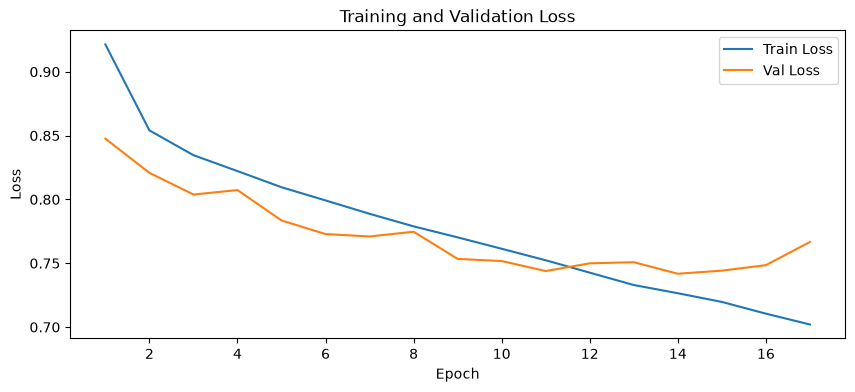

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.6496]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.6483]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.6801]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7321]

...

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7448]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7397]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7432]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7417]

Evaluation Batches:   0%|          | 0/32 [00:00<?, ?it/s, AvgLoss=0.7418]

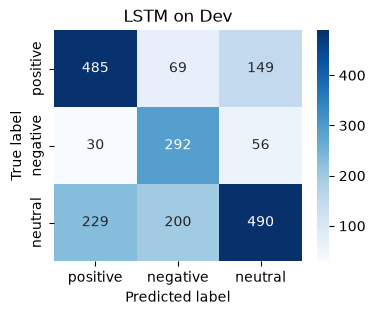


Validation Results:


semeval-tweets\twitter-dev-data.txt (LSTM): 0.614


In [23]:
# Clear CUDA cache
torch.cuda.empty_cache()

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Move training and validation data to device
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)
X_val_tensor   = X_val_tensor.to(device)
y_val_tensor   = y_val_tensor.to(device)

# Build class weights for CrossEntropyLoss
class_counts = Counter(y_train)
count_dict = dict(class_counts)
total = sum(count_dict.values())
weights = [total / count_dict[i] for i in ["positive", "negative", "neutral"]]
weights = torch.FloatTensor(weights).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
criterion = torch.nn.CrossEntropyLoss(weight=weights)

def train_epoch(model, X, y, optimizer, criterion, batch_size=64):
    """
    Trains for one epoch
    """
    model.train()
    epoch_loss = 0
    num_batches = (len(X) + batch_size - 1) // batch_size

    # Shuffle so batches differ every epoch
    perm = torch.randperm(len(X), device=X.device)

    pbar = tqdm(range(0, len(X), batch_size), desc="Training Batches", total=num_batches, leave=False)
    for start_idx in pbar:
        end_idx = min(start_idx + batch_size, len(X))
        batch_idx = perm[start_idx:end_idx]
        x_batch = X[batch_idx]
        y_batch = y[batch_idx]

        optimizer.zero_grad()
        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * x_batch.size(0)
        current_avg_loss = epoch_loss / end_idx
        pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})
    
    return epoch_loss / len(X)

def evaluate_nn(model, X, y, criterion, batch_size=64):
    """
    Perform validation pass
    """
    model.eval()
    epoch_loss = 0
    all_preds = []
    num_batches = (len(X) + batch_size - 1) // batch_size

    pbar = tqdm(range(0, len(X), batch_size), desc="Evaluation Batches", total=num_batches, leave=False)
    for start_idx in pbar:
        end_idx = min(start_idx + batch_size, len(X))
        x_batch = X[start_idx:end_idx]
        y_batch = y[start_idx:end_idx]

        with torch.no_grad():
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            epoch_loss += loss.item() * x_batch.size(0)
            all_preds.append(logits.argmax(dim=1).cpu().numpy())

            current_avg_loss = epoch_loss / end_idx
            pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})

    val_loss = epoch_loss / len(X)
    preds_concat = np.concatenate(all_preds)
    return val_loss, preds_concat

# Early stopping parameters
patience = 3
best_val_loss = float('inf')
epochs_without_improvement = 0

# Lists for plotting
train_losses = []
val_losses = []

num_epochs = 100
for epoch in range(num_epochs):
    # Train
    train_loss = train_epoch(model, X_train_tensor, y_train_tensor, optimizer, criterion, batch_size=batch_size)

    # Validation pass
    val_loss, val_preds = evaluate_nn(model, X_val_tensor, y_val_tensor, criterion, batch_size=batch_size)
    
    # Store for plots
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Print epoch summary
    print(f"Epoch {epoch+1:02d}: TrainLoss={train_loss:.4f}, ValLoss={val_loss:.4f}")

    # Early stopping based on val_loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1
        print(f"  {epochs_without_improvement} epochs without improvement in ValLoss.")
        if epochs_without_improvement >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs. No improvement in ValLoss for {patience} epochs.")
            break

# Restore the weights from the epoch with the lowest validation loss
model.load_state_dict(best_model_state)
print(f"Restored best model from epoch {best_epoch} (ValLoss={best_val_loss:.4f}).")

# Plots
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

model.eval()
_, final_val_preds = evaluate_nn(model, X_val_tensor, y_val_tensor, criterion, batch_size=batch_size)
y_val_np = y_val_tensor.cpu().numpy()

inv_sentiment_map = {0: "positive", 1: "negative", 2: "neutral"}
y_val_str = [inv_sentiment_map[i] for i in y_val_tensor.cpu().numpy()]
pred_str  = [inv_sentiment_map[i] for i in final_val_preds]

# Plot confusion matrix
plot_confusion_matrix(y_val_str, pred_str, title="LSTM on Dev")

print("\nValidation Results:")
eval_on_file("twitter-dev-data.txt", select_model="LSTM")

## Evaluation

### 🔍 Running Predictions on New Test Files

To evaluate a new test file, simply run:

`eval_on_file(file_path, select_model)`

This will automatically format the data, make predictions using the selected model (`"MaxEnt"`, `"LSVC"`, or `"LSTM"`), and print the Macro F1 score (positive/negative classes) using the provided `evaluate` function from the assignment skeleton.


In [24]:
# data_path = "semeval-tweets"

# Run eval on MaxEnt
print("----------Evaluating test scores for MaxEnt----------")
eval_on_file("twitter-test1.txt", select_model="MaxEnt")
eval_on_file("twitter-test2.txt", select_model="MaxEnt")
eval_on_file("twitter-test3.txt", select_model="MaxEnt")
print("\n")
# Run eval on LSVC
print("----------Evaluating test scores for LSVC------------")
eval_on_file("twitter-test1.txt", select_model="LSVC")
eval_on_file("twitter-test2.txt", select_model="LSVC")
eval_on_file("twitter-test3.txt", select_model="LSVC")
print("\n")
# Run eval on LSTM
print("----------Evaluating test scores for LSTM------------")
eval_on_file("twitter-test1.txt", select_model="LSTM")
eval_on_file("twitter-test2.txt", select_model="LSTM")
eval_on_file("twitter-test3.txt", select_model="LSTM")

----------Evaluating test scores for MaxEnt----------


semeval-tweets\twitter-test1.txt (MaxEnt): 0.616
semeval-tweets\twitter-test2.txt (MaxEnt): 0.630


semeval-tweets\twitter-test3.txt (MaxEnt): 0.562


----------Evaluating test scores for LSVC------------


semeval-tweets\twitter-test1.txt (LSVC): 0.617
semeval-tweets\twitter-test2.txt (LSVC): 0.632


semeval-tweets\twitter-test3.txt (LSVC): 0.553


----------Evaluating test scores for LSTM------------


semeval-tweets\twitter-test1.txt (LSTM): 0.626


semeval-tweets\twitter-test2.txt (LSTM): 0.599


semeval-tweets\twitter-test3.txt (LSTM): 0.547


In [25]:
# # Run eval on hidden test sets
# hidden_test_1 = ""
# hidden_test_2 = ""
# # Run eval on MaxEnt
# print("----------Evaluating hidden test scores for MaxEnt----------")
# eval_on_file(hidden_test_1, select_model="MaxEnt")
# eval_on_file(hidden_test_2, select_model="MaxEnt")
# print("\n")
# # Run eval on LSVC
# print("----------Evaluating hidden test scores for LSVC------------")
# eval_on_file(hidden_test_1, select_model="LSVC")
# eval_on_file(hidden_test_2, select_model="LSVC")
# print("\n")
# # Run eval on LSTM
# print("----------Evaluating hidden test scores for LSTM------------")
# eval_on_file(hidden_test_1, select_model="LSTM")
# eval_on_file(hidden_test_2, select_model="LSTM")